# Gemfinder pipeline: live demo

This is the short demo for the prototype review. It follows the same order as the slides. It uses made-up test cases plus one case from RYA's training data, and no real student responses.

What the pipeline adds to RYA's current method:
1. It **stops invalid inputs** instead of returning a number.
2. It **handles a small class against a national cohort** without retraining the network.
3. It **answers those edge cases reliably** instead of giving a misleading result.
4. It **shows how much a result depends on how reliable the question is**.
5. It **runs on an optimised network** that gives the same answers.

*To run it, open this notebook from the repo folder with the Python (scrp) kernel and choose Restart and Run All. It takes about a minute.*

In [1]:
from scrp_toolkit.pipeline.showcase import start
demo = start()      # loads RYA's network and the screening model, then runs all ten cases

## All ten cases at a glance

Each case compares two groups' answers to one survey question. Three columns give the answer from three sources:
- **Original** sends every comparison straight to RYA's network, which is what happens today.
- **Pipeline** is our version.
- **RYA simulation** is RYA's own model run many times, used as the reference answer.

In [2]:
demo.all_cases()

,what it is,original says,pipeline says,RYA simulation says,answered by,flag,why
case,,,,,,,
A,Typical comparison,meaningful,meaningful,meaningful,network,GREEN,all checks passed
B,"Class of 8 vs national group of 9,000",meaningful,not meaningful,not meaningful,fallback (simulation),AMBER,"small group (8) against one 1,125× larger"
C,Class of 25 vs national group,not meaningful,not meaningful,not meaningful,fallback (simulation),AMBER,small group (25) against one 360× larger
D,Everyone in one group gave the same answer,meaningful,meaningful,meaningful,fallback (simulation),AMBER,one group all gave the same answer
E,Broken reliability matrix (ρ),meaningful,no answer,–,rejected,RED,"ρ is invalid, so no answer is given"
F,Six-option question,not meaningful,no answer,–,rejected,RED,the network doesn't cover six-option questions
G,Group bigger than the network was trained on,not meaningful,not meaningful,not meaningful,fallback (simulation),AMBER,a group is bigger than the network was trained on
H,Question reliability from a small retest study,not meaningful,not meaningful,not meaningful,network,AMBER,answer could change with question reliability
I,"Same comparison, large retest study",not meaningful,not meaningful,not meaningful,network,GREEN,all checks passed


**Things to point out:** the pipeline matches RYA's simulation wherever it gives an answer. The original gets case B wrong. It also gives a number for E and F, which it shouldn't.

## Normal case: nothing changes
Most comparisons look like this one. Screening passes it, RYA's network answers as before, and the flag is GREEN.

In [3]:
demo.spotlight("A")

Case A: Typical comparison
  groups        : 113 vs 92 students
  original      : meaningful  (p < 0.001)
  pipeline      : meaningful  (p < 0.001, range below 0.001)
  answered by   : network
  flag          : GREEN – all checks passed


## O1 Screening: invalid inputs are stopped
Case E has a reliability matrix (ρ) that doesn't add up. Today it would still get a p-value. The pipeline rejects it before any calculation.

In [4]:
demo.spotlight("E")

Case E: Broken reliability matrix (ρ)
  groups        : 113 vs 92 students
  original      : meaningful  (p < 0.001)
  pipeline      : rejected before any calculation
  flag          : RED – ρ is invalid, so no answer is given


## O1 + O2: a class of 8 against the nation
Screening sees that the network wasn't built for this comparison and sends it to the fallback, which uses RYA's own simulation. The original answer, "meaningful", is wrong.

Case B: Class of 8 vs national group of 9,000
  groups        : 8 vs 9,000 students
  original      : meaningful  (p = 0.037)
  pipeline      : not meaningful  (p = 0.561, range 0.524–0.581)
  answered by   : fallback (simulation)
  flag          : AMBER – small group (8) against one 1,125× larger


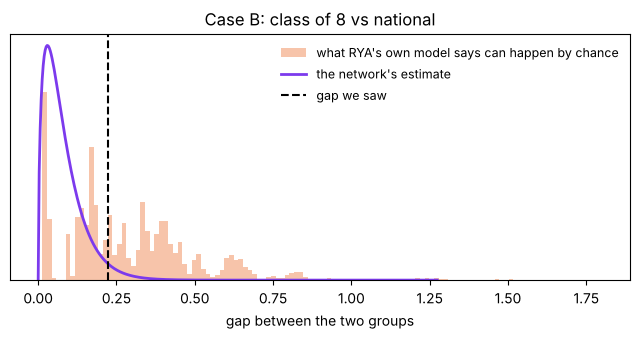

In [5]:
demo.spotlight("B")
demo.plot_case_b()

A class of 8 can only produce a few answer patterns, so the chance gaps fall into lumps (orange). The network's smooth curve (purple) is far too narrow. Against that curve the gap we saw looks extreme; against the real spread it is ordinary.

## O3 Uncertainty: how reliable is the question?
Cases H and I are the same comparison. What differs is how well we know the question's reliability: from a small retest study (H) or a large one (I). The p-value is the same, but for H the range crosses 0.05, so the answer could change. H gets AMBER.

In [6]:
demo.reliability()

,what it is,p-value,p-value range,crosses 0.05?,flag
case,,,,,
H,Question reliability from a small retest study,0.216,0.016 – 0.525,yes,AMBER
I,"Same comparison, large retest study",0.216,0.187 – 0.226,no,GREEN


## O4 Efficiency: still fast

In [7]:
timing, fp16_check = demo.speed()
print(fp16_check); timing

Half-size network (for the browser) gives the same decisions on all cases: True


,typical time per comparison
,
original (network only),2.6 ms
pipeline (all checks),26 ms


The extra checks take milliseconds per comparison, so a user won't notice them.

## Summary
| Capability | Shown by |
| --- | --- |
| Stops invalid inputs | E, F → RED |
| Handles a small class against the nation | B, C, J → screening flags, fallback answers |
| Answers edge cases reliably | matches RYA's simulation in every case answered |
| Shows dependence on question reliability | H (AMBER) vs I (GREEN) |
| Optimised network, same answers | half-size network, same decisions |

**Still open with RYA:** the real ε (0.1 is a placeholder for now), the portal's test code, and the test-retest counts for ρ.

The full step-by-step version is `pipeline_walkthrough.ipynb`.